<a href="https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/geo4bolivia_quickstart.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Find, load and understand Bolivia's subnational data with `geo4bolivia`

Part of the [GeoDevelopment Observatory of Bolivia](https://quarcs-lab.github.io/geo4bolivia/).

`geo4bolivia` is the observatory's Python package and the way into its data: the SDG Atlas of Bolivia 2026 (the Sustainable Development Index, 15 goal indices and 81 indicators near 2012 and near 2024), population, night-time lights and satellite embeddings, for Bolivia's 343 municipalities and indigenous autonomies. This notebook follows the [tutorial on the website](https://quarcs-lab.github.io/geo4bolivia/tools/geo4bolivia-package/):

1. **Discover** what is available, what each variable means and how to cite it
2. **Load** a panel, with and without the package
3. **Understand** a variable: summaries, labels and maps
4. **Compare the two periods**: change and rank mobility
5. **Move across scales**: municipalities, provinces, departments and the country
6. **Link your own table** by name or INE code
7. **Build an indicator from a raster**
8. **Interpolate to a grid** and **save** your dataset in the observatory's format

Every function is documented, with an example, in the [function reference](https://quarcs-lab.github.io/geo4bolivia/tools/geo4bolivia-reference/). The [three-packages notebook](https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/three_packages.ipynb) continues with the companion packages expdpy and geometrics.

## 0. Setup

In Google Colab the next cell installs the package (a few seconds: Colab already has its dependencies, including plotly for the interactive maps). Locally, `uv sync` has installed it already.

In [1]:
import importlib.util

if importlib.util.find_spec("geo4bolivia") is None:
    !pip install -q "geo4bolivia[raster]" mapclassify

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import plotly.express as px

import geo4bolivia as geo

print("geo4bolivia", geo.__version__)

geo4bolivia 0.5.0


## 1. Discover what is available

The catalog lists every dataset with its scale, its years and the number of units with data. The SDG Atlas has two periods for all 343 units; the datasets DS4Bolivia computed on the older 2015 map (population, lights, embeddings) cover the 333 municipalities whose territory has not changed since.

In [3]:
geo.datasets()[["dataset", "title", "years", "units", "variables"]]

,dataset,title,years,units,variables
0,pop,Population,2001–2020,333,2
1,ntl,Night-time lights per capita,2012–2020,333,2
2,sdg,"Sustainable Development Index, IDS (SDG Atlas ...","2012, 2024",343,4
3,sdg01,SDG 1: No poverty (SDG Atlas of Bolivia 2026),"2012, 2024",343,5
4,sdg02,SDG 2: Zero hunger (SDG Atlas of Bolivia 2026),"2012, 2024",343,8
5,sdg03,SDG 3: Good health and well-being (SDG Atlas o...,"2012, 2024",343,8
6,sdg04,SDG 4: Quality education (SDG Atlas of Bolivia...,"2012, 2024",343,12
7,sdg05,SDG 5: Gender equality (SDG Atlas of Bolivia 2...,"2012, 2024",343,7
8,sdg06,SDG 6: Clean water and sanitation (SDG Atlas o...,"2012, 2024",343,4
9,sdg07,SDG 7: Affordable and clean energy (SDG Atlas ...,"2012, 2024",343,5


`geo.search()` finds variables by words in their name, label or description, ignoring accents and case:

In [4]:
geo.search("poverty")[["dataset", "variable", "label", "years"]]

,dataset,variable,label,years
0,sdg01,index_sdg1,No poverty index (0-100),"2012, 2024"
1,sdg01,sdg1_2_mpi,Multidimensional poverty index (0-1),"2012, 2024"
2,sdg01,sdg1_4_eep,Energy poverty (% of dwellings),"2012, 2024"
3,sdg05,sdg5_1_pgm,Gender parity in multidimensional poverty (mal...,"2012, 2024"
4,sdg10,sdg10_2_pel,Parity of multidimensional poverty by ethnicit...,"2012, 2024"
5,sdg10,sdg10_2_mre,Parity of multidimensional poverty by migratio...,"2012, 2024"
6,sdg10,sdg10_2_tpm,Parity of multidimensional poverty for older p...,"2012, 2024"
7,sdg10,sdg10_2_gip,Gini coefficient of multidimensional poverty (...,"2012, 2024"
8,sdg05,index_sdg5,Gender equality index (0-100),"2012, 2024"
9,sdg10,index_sdg10,Reduced inequalities index (0-100),"2012, 2024"


`geo.info()` gathers a dataset's documentation: what it is, its coverage, the actual years behind its periods, its license, its sources and their licenses, the recommended citation and notes.

In [5]:
geo.info("sdg03")

SDG 3: Good health and well-being (SDG Atlas of Bolivia 2026)  [sdg03]

  The SDG 3 (Good health and well-being) index of the Atlas de los ODS en Bolivia 2026 (SDSN
  Bolivia) and the 7 indicators behind it, for Bolivia's 343 municipalities and indigenous
  autonomies (GAIOC), at two points in time: near the 2012 census and near the 2024 census,
  stored as 2012 and 2024 so that their change can be studied.

Coverage
  - 343 municipality units, 2012, 2024, 8 variables

Actual years behind the stored years (geo.reference_years)
  - 2012: ~2012; 2024: ~2024  (1 variables)
  - 2012: 2012; 2024: 2024  (2 variables)
  - 2012: 2008; 2024: 2023  (2 variables)
  - 2012: average 2011–2013; 2024: average 2022–2024  (3 variables)

License of the published files
  - Creative Commons Attribution 4.0 International License

Sources
  - Andersen, L. E., & Argandoña, F. (2026). Atlas de los ODS en Bolivia 2026: Brechas y
  tendencias del desarrollo sostenible en las Entidades Territoriales Autónomas, 2012–2024. La
  Paz: Universidad Privada Boliviana, SDSN Bolivia.
    License: No open license stated (© Universidad Privada Boliviana); used and shared with the
    permission of SDSN Bolivia

Cite as (geo.cite)
  GeoDevelopment Observatory of Bolivia (2026). SDG 3: Good health and well-being, from the
  Atlas de los ODS en Bolivia 2026 (343 municipalities, ~2012 and ~2024).
  https://github.com/quarcs-lab/geo4bolivia/blob/main/docs/datasets/sdg03.md

Notes
  - Both periods are stored at nominal years: 2012 for the Atlas's initial values (~2012) and
  2024 for its final values (~2024). Each indicator's actual reference years differ (e.g. 2008
  and 2023 for the health survey, three-year averages for volatile indicators) and are given in
  its description and in `geo:reference_years`.
  - Load one variable in both periods, e.g. `geo.load("sdg03", variables="index_sdg3",
  names=True)`, and its change per unit with `geo.change(df, "index_sdg3")`.
  - The units are the 343 municipalities and indigenous autonomies (GAIOC) of 2025. Four of them
  were created after the 2012 census (TIOC-Raqaypampa, San Pedro de Macha, TIOC-Jatun Ayllu Yura
  and TIOC-Territorio Indígena Multiétnico); the Atlas gives them values in both periods.
  - Aggregating to provinces, departments or Bolivia (`geo.aggregate`, `geo.combine`) averages
  the municipal values weighted by census population (`weighted_mean:population`; the 2012
  census for ~2012 and the 2024 census for ~2024, loaded from the `sdg` dataset through
  `geo:weights`): e.g. `geo.aggregate(geo.load("sdg03"), to="department", dataset="sdg03")`.
  These are population-weighted approximations, not the Atlas's own department figures.

Notebooks
  - Dynamics of sustainable development in Bolivia, 2012–2024
  - Poverty in Bolivia: an extended EDA and ESDA

Documentation: https://github.com/quarcs-lab/geo4bolivia/blob/main/docs/datasets/sdg03.md

The dictionary describes every column: readable label, definition, unit, aggregation rule and, when they differ from the stored years, the actual reference years.

In [6]:
geo.dictionary("sdg03")[["variable", "label", "unit", "aggregation", "reference_years"]]

,variable,label,unit,aggregation,reference_years
0,geo_id,Municipality ID,,,
1,year,Period,,,
2,mun_id,INE municipality code,,,
3,index_sdg3,Good health and well-being index (0-100),index (0-100),weighted_mean:population,2012: ~2012; 2024: ~2024
4,sdg3_1_cpp,Births attended by skilled health personnel (%),% of births,weighted_mean:population,2012: 2012; 2024: 2024
5,sdg3_2_tmi,"Infant mortality (per 1,000 live births)","deaths under 1 per 1,000 live births",weighted_mean:population,2012: 2008; 2024: 2023
6,sdg3_2_tmn,"Under-5 mortality (per 1,000 live births)","deaths under 5 per 1,000 live births",weighted_mean:population,2012: 2008; 2024: 2023
7,sdg3_3_vih,HIV incidence (per million people),cases per million people,weighted_mean:population,2012: average 2011–2013; 2024: average 2022–2024
8,sdg3_3_tub,"Tuberculosis incidence (per 100,000 people)","cases per 100,000 people",weighted_mean:population,2012: average 2011–2013; 2024: average 2022–2024
9,sdg3_3_vec,Vector-borne disease index (0-1),index (0-1),weighted_mean:population,2012: average 2011–2013; 2024: average 2022–2024


The Atlas stores its initial values at **2012** and its final values at **2024**, the years of the last two censuses, but some indicators come from other years: infant mortality, for example, from the health surveys of 2008 and 2023.

In [7]:
geo.reference_years("sdg03", "sdg3_2_tmi")

,variable,label,year,reference
0,sdg3_2_tmi,"Infant mortality (per 1,000 live births)",2012,2008
1,sdg3_2_tmi,"Infant mortality (per 1,000 live births)",2024,2023


If you use the data, cite the dataset and its original sources:

In [8]:
print(geo.cite("sdg03"))

GeoDevelopment Observatory of Bolivia (2026). SDG 3: Good health and well-being, from the Atlas de los ODS en Bolivia 2026 (343 municipalities, ~2012 and ~2024). https://github.com/quarcs-lab/geo4bolivia/blob/main/docs/datasets/sdg03.md

Please also credit the original sources:
- Please cite the Atlas and its data as: Andersen, L.E. & Argandoña, F. (2026). Atlas de los ODS en Bolivia 2026: Brechas y tendencias del desarrollo sostenible en las Entidades Territoriales Autónomas, 2012–2024. La Paz: Universidad Privada Boliviana, SDSN Bolivia.


## 2. Load a panel, with and without the package

### Without the package

Every published file is a plain URL, so pandas, geopandas, R, Stata or Excel can read it directly:

- **`data/<scale>/<dataset>.csv`**: the indicators, as a panel with one row per unit (`geo_id`) and year
- **`geo/units.csv`**: names, parent units and the codes other sources use (INE, DS4Bolivia, GADM)
- **`geo/boundaries/<scale>.geojson`**: polygons, keyed by the same `geo_id`

In [9]:
BASE = "https://raw.githubusercontent.com/quarcs-lab/geo4bolivia/main/"

# Inside a clone of the repository, read the local files instead (Colab uses the URLs)
local = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "geo" / "units.csv").is_file()), None)
if local is not None:
    BASE = local.as_posix() + "/"

sdg01 = pd.read_csv(BASE + "data/municipality/sdg01.csv")              # 343 units x 2 periods
units = pd.read_csv(BASE + "geo/units.csv", dtype={"ine_code": str})   # 466 units at 4 scales
municipalities = gpd.read_file(BASE + "geo/boundaries/municipality.geojson")
sdg01.head()

,geo_id,year,mun_id,index_sdg1,sdg1_2_mpi,sdg1_4_eep,sdg1_4_nbi,sdg1_4_ssb
0,BO-01-01-01,2012,10201,11.7,0.512,87.2,87.7,12.8
1,BO-01-01-01,2024,10201,35.7,0.187,82.0,71.7,29.6
2,BO-01-01-02,2012,10202,14.0,0.452,89.9,86.9,13.1
3,BO-01-01-02,2024,10202,38.9,0.133,84.6,69.7,33.5
4,BO-01-02-01,2012,10801,38.9,0.267,70.3,67.1,40.4


### With the package

`geo.load()` does the same in one line, and more: it picks variables and years, adds the unit names and the department or province each unit lies in, attaches boundaries, or reshapes to one column per year.

In [10]:
mpi = geo.load("sdg01", variables="sdg1_2_mpi", groups=["department"])
mpi.head()

,geo_id,name,year,department,sdg1_2_mpi
0,BO-01-01-01,Azurduy,2012,Chuquisaca,0.512
1,BO-01-01-01,Azurduy,2024,Chuquisaca,0.187
2,BO-01-01-02,Tarvita,2012,Chuquisaca,0.452
3,BO-01-01-02,Tarvita,2024,Chuquisaca,0.133
4,BO-01-02-01,Villa Serrano,2012,Chuquisaca,0.267


In [11]:
ids_2024 = geo.load("sdg", years=2024, geometry=True)          # a GeoDataFrame
pop_wide = geo.load("pop", variables="pop", wide="pop")         # one column per year
print(type(ids_2024).__name__, ids_2024.shape, "|", pop_wide.shape)

GeoDataFrame (343, 9) | (333, 21)


`geo.units()` has every unit's name, parents and source codes:

In [12]:
geo.units("municipality")[["geo_id", "name", "ine_code", "province_id", "department_id", "area_km2"]].head()

,geo_id,name,ine_code,province_id,department_id,area_km2
0,BO-01-01-01,Azurduy,010201,BO-01-01,BO-01,1729.28
1,BO-01-01-02,Tarvita,010202,BO-01-01,BO-01,1354.24
2,BO-01-02-01,Villa Serrano,010801,BO-01-02,BO-01,1730.36
3,BO-01-03-01,Huacareta,010502,BO-01-03,BO-01,2963.81
4,BO-01-03-02,Monteagudo,010501,BO-01-03,BO-01,3379.79


The Multidimensional Poverty Index (`sdg1_2_mpi`, 0 to 1, higher = poorer) comes from the censuses themselves. With the same classes in both maps, the change is plain to see:

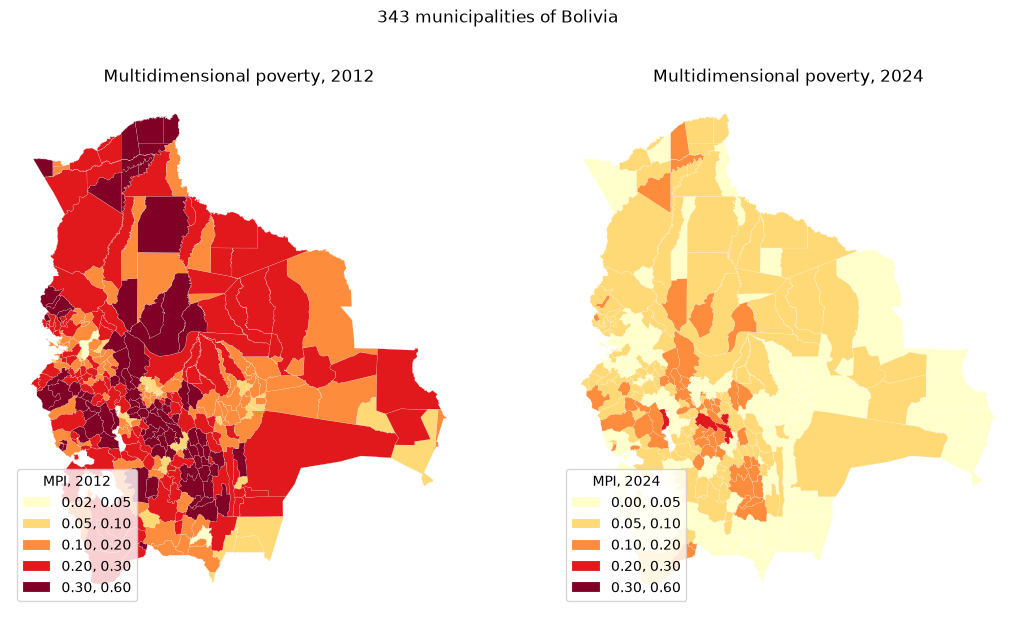

In [13]:
mpi_map = municipalities.merge(sdg01[["geo_id", "year", "sdg1_2_mpi"]], on="geo_id")
bins = {"bins": [0.05, 0.1, 0.2, 0.3, 0.6]}

fig, axes = plt.subplots(1, 2, figsize=(13, 7))
for ax, year in zip(axes, [2012, 2024]):
    mpi_map[mpi_map["year"] == year].plot(
        column="sdg1_2_mpi", cmap="YlOrRd", scheme="user_defined", classification_kwds=bins,
        legend=True, legend_kwds={"title": f"MPI, {year}", "loc": "lower left"},
        edgecolor="white", linewidth=0.1, ax=ax)
    ax.set_axis_off()
    ax.set_title(f"Multidimensional poverty, {year}")
fig.suptitle("343 municipalities of Bolivia");

## 3. Understand a variable

`geo.describe()` summarises variables per period, with their labels and units; `by=` summarises each group instead.

In [14]:
edu = geo.load("sdg04", variables=["index_sdg4", "sdg4_6_alf"], groups=["department"])
geo.describe(edu)

,variable,label,unit,year,count,mean,std,min,p25,median,p75,max
0,index_sdg4,Quality education index (0-100),index (0-100),2012,343,47.559767,10.575112,18.6,42.15,47.6,53.35,84.8
1,index_sdg4,Quality education index (0-100),index (0-100),2024,343,69.047522,8.753478,43.5,64.00,69.5,74.35,94.7
2,sdg4_6_alf,"Literacy rate, 15+ (%)",% of people 15+,2012,343,91.731195,5.878491,68.3,88.65,93.7,95.90,100.0
3,sdg4_6_alf,"Literacy rate, 15+ (%)",% of people 15+,2024,343,93.355102,4.928841,73.0,91.35,94.9,96.80,99.5


In [15]:
geo.describe(edu, variables="index_sdg4", by="department")

,variable,label,unit,department,count,mean,std,min,p25,median,p75,max
0,index_sdg4,Quality education index (0-100),index (0-100),Beni,40,56.280000,13.559805,23.5,45.650,57.25,67.075,84.2
1,index_sdg4,Quality education index (0-100),index (0-100),Chuquisaca,58,55.443103,14.218867,29.2,46.825,55.05,68.700,91.4
2,index_sdg4,Quality education index (0-100),index (0-100),Cochabamba,96,57.290625,17.106361,18.9,45.225,57.05,69.650,93.2
3,index_sdg4,Quality education index (0-100),index (0-100),La Paz,174,59.732184,12.634268,29.7,49.050,61.75,69.900,94.7
4,index_sdg4,Quality education index (0-100),index (0-100),Oruro,70,63.585714,12.656158,39.2,52.050,64.25,73.975,92.6
5,index_sdg4,Quality education index (0-100),index (0-100),Pando,30,52.746667,15.856745,29.4,37.500,56.85,65.225,82.1
6,index_sdg4,Quality education index (0-100),index (0-100),Potosí,84,54.938095,17.513278,18.6,42.225,55.80,67.500,89.7
7,index_sdg4,Quality education index (0-100),index (0-100),Santa Cruz,112,59.097321,12.083788,37.8,47.575,59.25,69.525,87.1
8,index_sdg4,Quality education index (0-100),index (0-100),Tarija,22,62.227273,14.119665,36.7,49.025,63.10,73.475,89.5


`geo.labels()` names any column for a plot, and `geo.map()` draws an interactive map (hover over a municipality to see its name and value):

In [16]:
px.box(edu, x="department", y="sdg4_6_alf", color="year", labels=geo.labels(edu),
       title="Literacy by department, ~2012 and ~2024")

In [17]:
geo.map(edu, "index_sdg4", year=2024)

## 4. Compare the two periods

`geo.change()` turns a panel into one row per unit: its first and last values, the absolute, percentage and annual change, and its rank in each period (1 = highest).

In [18]:
ids = geo.load("sdg", variables="index_sdg", groups=["department"])
chg = geo.change(ids, "index_sdg")
chg.nlargest(5, "index_sdg_change")[["name", "department", "index_sdg_2012", "index_sdg_2024", "index_sdg_change"]]

,name,department,index_sdg_2012,index_sdg_2024,index_sdg_change
194,Cruz de Machacamarca,Oruro,42.9,63.4,20.5
199,Carangas,Oruro,43.4,62.8,19.4
42,Sicaya,Cochabamba,42.8,60.4,17.6
67,Villa Gualberto Villarroel,Cochabamba,43.4,60.3,16.9
201,Todos Santos,Oruro,44.4,61.2,16.8


In [19]:
print(f"The IDS rose in {(chg['index_sdg_change'] > 0).sum()} of {len(chg)} units, "
      f"by {chg['index_sdg_change'].mean():.1f} points on average.")
r = np.corrcoef(chg["index_sdg_2012"], chg["index_sdg_change"])[0, 1]
print(f"Correlation between the initial level and the change: {r:.2f}")

The IDS rose in 342 of 343 units, by 10.0 points on average.
Correlation between the initial level and the change: -0.43


The units that started lower gained more. Ranks moved too: points above the diagonal fell in the ranking, points below it climbed.

In [20]:
px.scatter(chg, x="index_sdg_rank_2012", y="index_sdg_rank_2024", color="department",
           hover_name="name", labels=geo.labels(chg),
           title="Rank mobility in the Sustainable Development Index (1 = highest)")

## 5. Move across scales

Every geo ID nests by prefix: municipality `BO-04-17-04` lies in province `BO-04-17`, in department `BO-04`, in Bolivia `BO`. `geo.aggregate()` moves a panel up with each variable's rule from the metadata. The SDG indicators average with census-population weights (the 2012 census for ~2012, the 2024 census for ~2024), which the package loads from the `sdg` dataset by itself. These are approximations, not the Atlas's own department figures. `n_units` and `coverage` tell how many municipalities each result rests on.

In [21]:
up = geo.aggregate(mpi, to=["department", "country"], dataset="sdg01")
up.tail(4)

,geo_id,scale,year,sdg1_2_mpi,n_units,coverage
16,BO-09,department,2012,0.079347,11,1.0
17,BO-09,department,2024,0.017672,11,1.0
18,BO,country,2012,0.133185,343,1.0
19,BO,country,2024,0.033046,343,1.0


In [22]:
dep = geo.add_names(up[up["scale"] == "department"])
px.line(dep, x="year", y="sdg1_2_mpi", color="name", markers=True, labels=geo.labels(dep),
        title="Multidimensional poverty by department (census-population weighted)")

Night-time lights cover 333 of the 343 municipalities, and the coverage shows it. Their logs have no aggregation rule, so an explicit rule is needed:

In [23]:
geo.aggregate(geo.load("ntl", years=2020), to="department", rules={"ln_NTLpc": "mean"},
              variables="ln_NTLpc")[["geo_id", "ln_NTLpc", "n_units", "coverage"]]

,geo_id,ln_NTLpc,n_units,coverage
0,BO-01,13.782270,29,1.000000
1,BO-02,14.479835,46,0.958333
2,BO-03,13.634814,17,0.850000
3,BO-04,13.359547,87,1.000000
4,BO-05,14.081636,35,1.000000
5,BO-06,12.719444,15,1.000000
6,BO-07,13.658344,37,0.880952
7,BO-08,14.555343,56,1.000000
8,BO-09,14.986451,11,1.000000


`geo.combine()` puts several datasets on one scale, aggregating them as needed:

In [24]:
goals = geo.add_names(geo.combine(["sdg03", "sdg04"], scale="department", years=2024))
px.scatter(goals, x="index_sdg3", y="index_sdg4", text="name", labels=geo.labels(goals),
           title="Health and education by department, ~2024")

## 6. Link your own table

Tables from reports and ministries identify units by name, spelled in many ways, or by INE code. `geo.link()` attaches the observatory's `geo_id`. It ignores accents, case, spaces and punctuation, and tries every name and code column in `geo.units()`.

The values below are **made up** for the demonstration; replace them with your own data.

In [25]:
mine = pd.DataFrame({
    "Departamento": ["LA PAZ", "Cochabamba", "Santa Cruz", "Potosi", "Chuquisaca", "La Paz"],
    "year":         [2024, 2024, 2024, 2024, 2024, 2025],
    "clinics":      [412, 301, 388, 266, 190, 420],          # illustrative values
})
mine = geo.link(mine, scale="department", on="Departamento")
mine

,geo_id,Departamento,year,clinics
0,BO-04,LA PAZ,2024,412
1,BO-02,Cochabamba,2024,301
2,BO-08,Santa Cruz,2024,388
3,BO-07,Potosi,2024,266
4,BO-01,Chuquisaca,2024,190
5,BO-04,La Paz,2025,420


In [26]:
geo.check(mine, scale="department")        # [] = a valid panel: known ids, one row per unit and year

[]

Municipal statistics from INE (and every DS4Bolivia table) carry codes. Link them by code: INE's 6-digit `ine_code`, the same code as a number (`mun_id`), or DS4Bolivia's `asdf_id`. The names follow the Atlas, so the capital is *Nuestra Señora de La Paz*:

In [27]:
ine = pd.DataFrame({"codigo": [20101, 20105, 70101, 30101, 10101], "teachers": [9120, 6211, 11034, 5980, 2870]})
geo.add_names(geo.link(ine, scale="municipality", on="codigo", key="mun_id"), groups=["department"])

,geo_id,name,department,codigo,teachers
0,BO-04-17-04,Nuestra Señora de La Paz,La Paz,20101,9120
1,BO-04-17-02,El Alto,La Paz,20105,6211
2,BO-08-01-05,Santa Cruz de la Sierra,Santa Cruz,70101,11034
3,BO-02-08-01,Cochabamba,Cochabamba,30101,5980
4,BO-01-06-02,Sucre,Chuquisaca,10101,2870


Older spellings still link: by default `geo.link()` also tries `name_ds4bolivia` and `name_gadm`, so "La Paz" finds the capital. A name shared by several municipalities, or a typo, stops with an explanation instead of silently linking the wrong unit:

In [28]:
for value in ["San Javier", "Cochabmba"]:
    try:
        geo.link(pd.DataFrame({"m": [value]}), scale="municipality", on="m", key="name")
    except ValueError as err:
        print(err, "\n")

1 row(s) of 'm' name several municipality units and were not linked: 'San Javier' (BO-03-01-01, BO-08-10-04). Link them by a code (key=...) instead. 

1 value(s) of 'm' match no municipality 'name': 'Cochabmba' (did you mean 'Cochabamba'?). Fix them, e.g. df['m'] = df['m'].replace({...}), or pass errors='warn'. 



## 7. Build an indicator from a raster

`geo.zonal()` summarises any GeoTIFF (for example an export from Google Earth Engine, or a WorldPop population grid) over the units of a scale. As a self-contained example, we compute a raster of **distance to the nearest of Bolivia's three largest cities** (La Paz, Cochabamba and Santa Cruz de la Sierra, the "central axis"), a simple proxy of market access, and average it over municipalities.

In [29]:
import rasterio
from rasterio.transform import from_bounds

CITIES = {"La Paz": (-16.4955, -68.1336), "Cochabamba": (-17.3895, -66.1568), "Santa Cruz": (-17.7833, -63.1821)}

x0, y0, x1, y1 = geo.boundaries("country").total_bounds
nx, ny = 900, 1000                                             # about 1.5 km pixels
LON, LAT = np.meshgrid(np.linspace(x0, x1, nx), np.linspace(y1, y0, ny))

def haversine_km(lat, lon, lat0, lon0):
    lat, lon, lat0, lon0 = map(np.radians, (lat, lon, lat0, lon0))
    a = np.sin((lat - lat0) / 2) ** 2 + np.cos(lat0) * np.cos(lat) * np.sin((lon - lon0) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

km = np.min([haversine_km(LAT, LON, la, lo) for la, lo in CITIES.values()], axis=0)

with rasterio.open("distance_to_main_cities.tif", "w", driver="GTiff", width=nx, height=ny, count=1,
                   dtype="float32", crs="EPSG:4326", transform=from_bounds(x0, y0, x1, y1, nx, ny)) as dst:
    dst.write(km.astype("float32"), 1)

access = geo.zonal("distance_to_main_cities.tif", scale="municipality", stats=["mean", "max"], name="dist_axis_km")
access.head()

,geo_id,dist_axis_km_mean,dist_axis_km_max
0,BO-01-01-01,297.976007,328.039978
1,BO-01-01-02,265.125369,289.335236
2,BO-01-02-01,176.702818,197.327393
3,BO-01-03-01,325.066672,367.762909
4,BO-01-03-02,265.958876,325.305908


Is distance to the central axis associated with poverty, and has that changed? Join the new indicator to the poverty data of both periods:

In [30]:
d = mpi.merge(access, on="geo_id")
for year, g in d.groupby("year"):
    print(f"{year}: correlation {g['dist_axis_km_mean'].corr(g['sdg1_2_mpi']):.2f}")
px.scatter(d, x="dist_axis_km_mean", y="sdg1_2_mpi", facet_col="year", hover_name="name",
           labels={**geo.labels(d), "dist_axis_km_mean": "Mean distance to La Paz, Cochabamba or Santa Cruz (km)"},
           title="Poverty and distance to the central axis")

2012: correlation 0.14
2024: correlation 0.04


Only weakly: municipalities far from the three cities were slightly poorer in 2012, and by 2024 the association has almost vanished.

## 8. Interpolate to a grid and save

Grids, watersheds or a different municipality map do not nest in the administrative hierarchy. `geo.overlay()` moves data onto them by area weights. Totals (`extensive`) are split by area; rates (`intensive`) are area-weighted means.

municipalities: 11,364,933  grid: 11,364,933


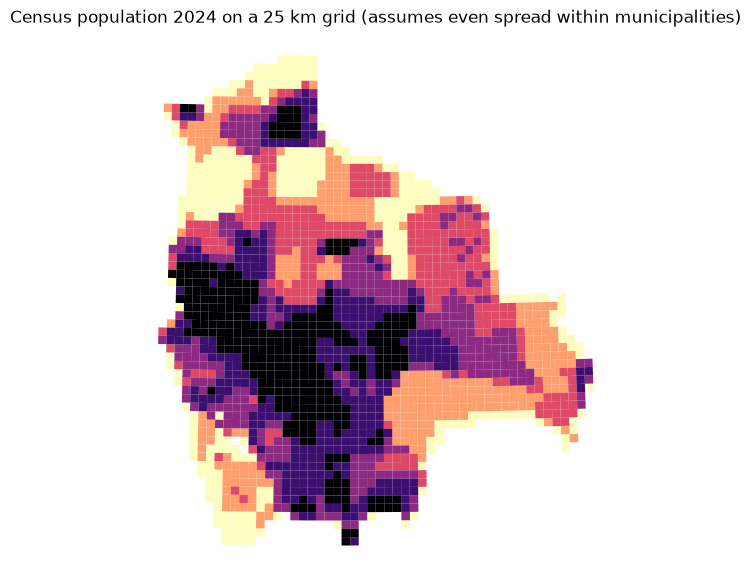

In [31]:
from shapely.geometry import box

crs = geo.config()["equal_area_crs"]                          # Albers equal-area fitted to Bolivia, metres
country = geo.boundaries("country").to_crs(crs)
gx0, gy0, gx1, gy1 = country.total_bounds
size = 25_000
cells = [box(x, y, x + size, y + size) for x in np.arange(gx0, gx1, size) for y in np.arange(gy0, gy1, size)]
grid = gpd.GeoDataFrame({"cell": [f"c{i}" for i in range(len(cells))]}, geometry=cells, crs=crs)
grid = grid[grid.intersects(country.geometry.iloc[0])].to_crs("EPSG:4326")

census_2024 = geo.load("sdg", variables="population", years=2024)
on_grid = geo.overlay(census_2024, grid, extensive=["population"], id_col="cell")
print(f"municipalities: {census_2024['population'].sum():,.0f}  grid: {on_grid['population'].sum():,.0f}")   # totals are kept

ax = grid.merge(on_grid.rename(columns={"geo_id": "cell"}), on="cell").plot(
    column="population", cmap="magma_r", scheme="quantiles", k=6, figsize=(7, 7))
ax.set_axis_off(); ax.set_title("Census population 2024 on a 25 km grid (assumes even spread within municipalities)");

Finally, save your indicator exactly like the published datasets: CSV, Parquet and a Frictionless datapackage describing every variable. It is then easy to share, reload or contribute to the observatory ([CONTRIBUTING_DATA.md](https://github.com/quarcs-lab/geo4bolivia/blob/main/CONTRIBUTING_DATA.md)).

In [32]:
access["year"] = 2024
geo.save(access[["geo_id", "year", "dist_axis_km_mean", "dist_axis_km_max"]], "market_access", scale="municipality",
         directory="my_data", title="Distance to the central axis",
         description="Mean and maximum straight-line distance from each municipality to the nearest of La Paz, Cochabamba and Santa Cruz de la Sierra.",
         variables={"dist_axis_km_mean": {"label": "Mean distance to the central axis (km)",
                                          "description": "Mean distance to the nearest main city", "unit": "km", "aggregation": "none"},
                    "dist_axis_km_max": {"label": "Maximum distance to the central axis (km)",
                                         "description": "Maximum distance to the nearest main city", "unit": "km", "aggregation": "max"}})

wrote my_data/data/municipality/market_access.csv, my_data/data/municipality/market_access.parquet and my_data/metadata/market_access.datapackage.json


{'name': 'market_access',
 'title': 'Distance to the central axis',
 'description': 'Mean and maximum straight-line distance from each municipality to the nearest of La Paz, Cochabamba and Santa Cruz de la Sierra.',
 'version': '1.0.0',
 'licenses': [{'name': 'CC-BY-4.0'}],
 'sources': [],
 'geo:categories': [],
 'geo:notes': [],
 'resources': [{'name': 'market_access-municipality',
   'path': 'https://raw.githubusercontent.com/quarcs-lab/geo4bolivia/main/data/municipality/market_access.csv',
   'format': 'csv',
   'mediatype': 'text/csv',
   'encoding': 'utf-8',
   'geo:scale': 'municipality',
   'geo:period': [2024, 2024],
   'geo:path': 'data/municipality/market_access.csv',
   'geo:parquet': 'data/municipality/market_access.parquet',
   'schema': {'primaryKey': ['geo_id', 'year'],
    'fields': [{'name': 'geo_id',
      'title': 'Municipality (343) ID',
      'type': 'string',
      'description': 'Municipality (343) geo ID',
      'geo:role': 'id',
      'constraints': {'required'

## Next steps

- One question through the three packages (geo4bolivia, expdpy, geometrics): [`three_packages.ipynb`](https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/three_packages.ipynb)
- Change, convergence and rank mobility of the 15 goals: [`sdg_dynamics.ipynb`](https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/sdg_dynamics.ipynb)
- Every function, with an example: the [function reference](https://quarcs-lab.github.io/geo4bolivia/tools/geo4bolivia-reference/)
- The full guide: [how the data infrastructure works](https://github.com/quarcs-lab/geo4bolivia/blob/main/docs/data-infrastructure.md)
- Every function also has help: `help(geo.change)`